In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)


In [2]:
# Load the dataset

df = pd.read_csv("../dataset/heart_disease_dataset.csv")

# Display first 5 rows
df.head()


,Age,Gender,Cholesterol,Blood Pressure,Heart Rate,Smoking,Alcohol Intake,Exercise Hours,Family History,Diabetes,Obesity,Stress Level,Blood Sugar,Exercise Induced Angina,Chest Pain Type,Heart Disease
0,75,Female,228,119,66,Current,Heavy,1,No,No,Yes,8,119,Yes,Atypical Angina,1
1,48,Male,204,165,62,Current,NaN,5,No,No,No,9,70,Yes,Typical Angina,0
2,53,Male,234,91,67,Never,Heavy,3,Yes,No,Yes,5,196,Yes,Atypical Angina,1
3,69,Female,192,90,72,Current,NaN,4,No,Yes,No,7,107,Yes,Non-anginal Pain,0
4,62,Female,172,163,93,Never,NaN,6,No,Yes,No,2,183,Yes,Asymptomatic,0


In [3]:
# Display number of rows and columns

print("Dataset Shape:", df.shape)


Dataset Shape: (1000, 16)


In [4]:
# Display column names

print(df.columns)


Index(['Age', 'Gender', 'Cholesterol', 'Blood Pressure', 'Heart Rate',
       'Smoking', 'Alcohol Intake', 'Exercise Hours', 'Family History',
       'Diabetes', 'Obesity', 'Stress Level', 'Blood Sugar',
       'Exercise Induced Angina', 'Chest Pain Type', 'Heart Disease'],
      dtype='str')


In [5]:
# Display data types

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Age                      1000 non-null   int64
 1   Gender                   1000 non-null   str  
 2   Cholesterol              1000 non-null   int64
 3   Blood Pressure           1000 non-null   int64
 4   Heart Rate               1000 non-null   int64
 5   Smoking                  1000 non-null   str  
 6   Alcohol Intake           660 non-null    str  
 7   Exercise Hours           1000 non-null   int64
 8   Family History           1000 non-null   str  
 9   Diabetes                 1000 non-null   str  
 10  Obesity                  1000 non-null   str  
 11  Stress Level             1000 non-null   int64
 12  Blood Sugar              1000 non-null   int64
 13  Exercise Induced Angina  1000 non-null   str  
 14  Chest Pain Type          1000 non-null   str  
 15  Heart Disease   

In [6]:
# Check missing values

print(df.isnull().sum())


Age                          0
Gender                       0
Cholesterol                  0
Blood Pressure               0
Heart Rate                   0
Smoking                      0
Alcohol Intake             340
Exercise Hours               0
Family History               0
Diabetes                     0
Obesity                      0
Stress Level                 0
Blood Sugar                  0
Exercise Induced Angina      0
Chest Pain Type              0
Heart Disease                0
dtype: int64


In [7]:
# Check target class distribution

print(df["Heart Disease"].value_counts())


Heart Disease
0    608
1    392
Name: count, dtype: int64


In [8]:
# X contains input features
# y contains the target variable

X = df.drop("Heart Disease", axis=1)

y = df["Heart Disease"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (1000, 15)
Target Shape: (1000,)


In [9]:
# Identify numerical columns

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Identify categorical columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

print("Numerical Features:")
print(list(numerical_features))

print("\nCategorical Features:")
print(list(categorical_features))


Numerical Features:
['Age', 'Cholesterol', 'Blood Pressure', 'Heart Rate', 'Exercise Hours', 'Stress Level', 'Blood Sugar']

Categorical Features:
['Gender', 'Smoking', 'Alcohol Intake', 'Family History', 'Diabetes', 'Obesity', 'Exercise Induced Angina', 'Chest Pain Type']


E:\temp\ipykernel_1892\3960368941.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [10]:
# Preprocessing for numerical and categorical features

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),

        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)


In [11]:
# Create Random Forest classifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)


In [12]:
# Combine preprocessing and Random Forest model

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", rf_model)
    ]
)


In [13]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)


Training Data: (800, 15)
Testing Data: (200, 15)


In [14]:
# Train the model

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")


Random Forest Model Trained Successfully!


In [15]:
# Predict on training data

y_train_pred = model.predict(X_train)

# Predict on testing data

y_test_pred = model.predict(X_test)

print("Predictions Generated Successfully!")


Predictions Generated Successfully!


In [16]:
# Calculate evaluation metrics

train_accuracy = accuracy_score(y_train, y_train_pred)

test_accuracy = accuracy_score(y_test, y_test_pred)

precision = precision_score(y_test, y_test_pred)

recall = recall_score(y_test, y_test_pred)

f1 = f1_score(y_test, y_test_pred)

print("Training Accuracy :", round(train_accuracy, 4))
print("Testing Accuracy  :", round(test_accuracy, 4))
print("Precision         :", round(precision, 4))
print("Recall            :", round(recall, 4))
print("F1 Score          :", round(f1, 4))


Training Accuracy : 1.0
Testing Accuracy  : 0.99
Precision         : 1.0
Recall            : 0.9744
F1 Score          : 0.987


In [17]:
# Predict probabilities

y_test_proba = model.predict_proba(X_test)[:, 1]

# Calculate ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

# Calculate AUC

auc_score = roc_auc_score(y_test, y_test_proba)

print("ROC-AUC Score:", round(auc_score, 4))


ROC-AUC Score: 1.0


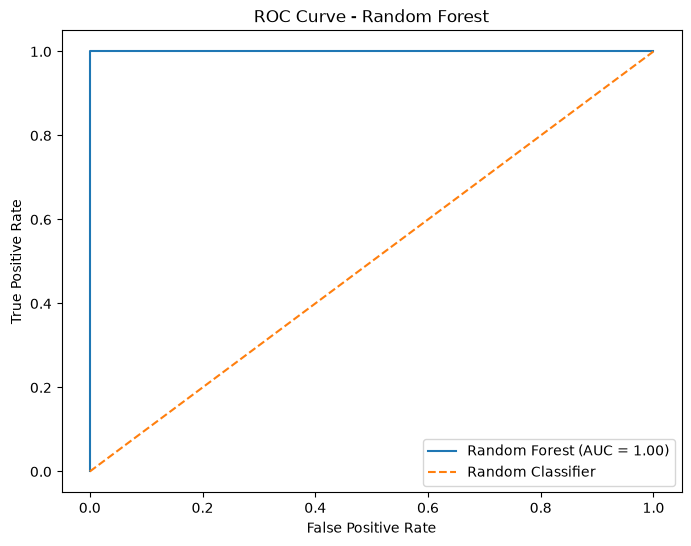

In [18]:
# Plot ROC Curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.2f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Random Forest")

plt.legend()

plt.show()
